# Smile risk through calibration

Market vegas $\partial PV/\partial\sigma_i$ come from the IFT solve in `SliceSVI.bscall`.
Projecting them onto a shape $g(K)$ gives the first-order PV change when every quote moves by $\varepsilon\, g(K_i)$ and the slice is refitted:
$$\frac{d PV}{d\varepsilon} = \sum_i \frac{\partial PV}{\partial \sigma_i}\, g(K_i).$$
Shapes, with $x = (K - S_0)/S_0$: flat $g=1$, skew $g=x$, smile $g=x^2$. Decision log: `smile_risk_log.md`.

In [1]:
import numpy as np
import matplotlib.pyplot as mpl
from svi import SliceSVI
from svi_ift import jacobian_svi

# figure style shared with the other posts: one column of panels, readable at 650px
mpl.rcParams.update({
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "lines.linewidth": 1.8, "grid.linestyle": "dashed", "grid.alpha": 0.6,
})

IMG = "/Users/ptamarov/ptamarov.github.io/posts/images/"
spot, tau, r = 100, 1.00, 0.035
strikes = np.concatenate([np.arange(5, 105, 2.5), np.arange(105, 260, 5)])
fwd = spot * np.exp(r * tau)
zs = np.log(strikes / fwd)  # quotes in log-moneyness to the forward, as the pricer reads SVI

# not an SVI slice, so the fit has nonzero residuals
def myvol(z):
    return 0.1 * (np.tanh(2 * z) - 0.3) * (0.5 + z) + 0.215

ivs = myvol(zs)
base = SliceSVI(tau)
base.fit(zs, ivs)
print(base.params, base.min_variance)

[-0.07367907  0.11829051 -0.03592996 -0.22949979  0.95964982] 0.039765096895800656


In [2]:
from scipy.stats import norm
from svi_ift import residual_h

res_vol = base.bsvol(zs) - ivs
J = jacobian_svi(zs, base.params)
R = residual_h(base.residuals, zs, base.params)
print(f"max |resid| {1e4 * np.abs(res_vol).max():.1f}bp vol, rms {1e4 * np.sqrt(np.mean(res_vol**2)):.1f}bp")
print(f"|R| / |J^T J| = {np.linalg.norm(R) / np.linalg.norm(J.T @ J):.2e}")

fwd = spot * np.exp(r * tau)
for k in [50, 100, 150]:
    sig = base.bsvol(np.array([np.log(k / fwd)]))[0]
    d1 = (np.log(fwd / k) + 0.5 * sig**2 * tau) / (sig * np.sqrt(tau))
    base.bscall(spot, k, r, tau)
    print(f"K={k}: fitted vol {sig:.4f}, BS vega {np.exp(-r * tau) * fwd * np.sqrt(tau) * norm.pdf(d1):.4f}, "
          f"flat vega {np.sum(base.pricing_results['vegas']):.4f}")

max |resid| 68.8bp vol, rms 37.3bp
|R| / |J^T J| = 4.03e-06
K=50: fitted vol 0.2374, BS vega 0.2496, flat vega 0.2497
K=100: fitted vol 0.2033, BS vega 38.4263, flat vega 37.9704
K=150: fitted vol 0.2401, BS vega 14.4962, flat vega 14.5796


In [3]:
# per-quote vegas: bump each quote by ±10bp of vol and refit, vs AAD + IFT
def bumped_vegas(k, eps=1e-3):
    out = np.zeros_like(ivs)
    for i in range(len(ivs)):
        pv = []
        for sg in (1, -1):
            sl = SliceSVI(tau)
            sl.fit(zs, ivs + sg * eps * (np.arange(len(ivs)) == i), guess=base.params)
            sl.bscall(spot, k, r, tau)
            pv.append(sl.pricing_results["netvalue"])
        out[i] = (pv[0] - pv[1]) / (2 * eps)
    return out

bumped = {}
for k in [50, 100, 150]:
    base.bscall(spot, k, r, tau)
    v = base.pricing_results["vegas"]
    bumped[k] = bumped_vegas(k)
    d = bumped[k] - v
    print(f"K={k}: max |bump - AAD| = {np.abs(d).max():.2e} = {np.abs(d).max() / np.sum(v):.1e} of flat vega")

K=50: max |bump - AAD| = 1.69e-05 = 6.8e-05 of flat vega
K=100: max |bump - AAD| = 3.70e-03 = 9.8e-05 of flat vega
K=150: max |bump - AAD| = 1.37e-03 = 9.4e-05 of flat vega


In [4]:
x = (strikes - spot) / spot
shapes = {"flat": np.ones_like(x), "skew": x, "smile": x**2}

def refit_risk(k, g, eps=1e-4):
    pv = []
    for sg in (1, -1):
        sl = SliceSVI(tau)
        sl.fit(zs, ivs + sg * eps * g, guess=base.params)
        sl.bscall(spot, k, r, tau)
        pv.append(sl.pricing_results["netvalue"])
    return (pv[0] - pv[1]) / (2 * eps)

rows = []
for k in [50, 100, 150]:
    base.bscall(spot, k, r, tau)
    vegas = base.pricing_results["vegas"]
    for name, g in shapes.items():
        rows.append((k, name, vegas @ g, refit_risk(k, g)))
for k, name, a, b in rows:
    print(f"K={k:>3}  {name:<5}  AAD={a:9.4f}  refit={b:9.4f}")

K= 50  flat   AAD=   0.2497  refit=   0.2497
K= 50  skew   AAD=  -0.1258  refit=  -0.1257
K= 50  smile  AAD=   0.0840  refit=   0.0840
K=100  flat   AAD=  37.9704  refit=  37.9795
K=100  skew   AAD=  -0.7205  refit=  -0.7249
K=100  smile  AAD=  -5.7831  refit=  -5.7920
K=150  flat   AAD=  14.5796  refit=  14.5770
K=150  skew   AAD=   7.9951  refit=   7.9899
K=150  smile  AAD=   5.5162  refit=   5.5174


Flat vega (`np.sum(vegas)`) is close to, but not equal to, the Black–Scholes vega at the fitted vol (cell 2). Note the sums depend on the strike grid (spacing 2.5 below 105, 5 above).

## Comparison: SVI-parameter directions
Bumping quotes along $\partial\sigma_{\rm SVI}/\partial\theta_j$ is a move the fit absorbs exactly, so the projection reproduces $\partial PV/\partial\theta_j$.

In [5]:
vol = np.sqrt(base.bstermvar(zs) / tau)
Jv = jacobian_svi(zs, base.params) / (2 * tau * vol)[:, None]  # dσ/dθ
base.bscall(spot, 100, r, tau)
vegas = base.pricing_results["vegas"]
for j, n in enumerate(["a", "b", "rho", "m", "s"]):
    print(n, vegas @ Jv[:, j], refit_risk(100, Jv[:, j]))

a 93.8317996548939 93.8407785082962
b 91.45401294904049 91.46292925510835
rho 2.1655185898840736 2.164066214511706
m -1.8336233624637963 -1.7975859031782448
s 10.940148086950558 10.922483458344345


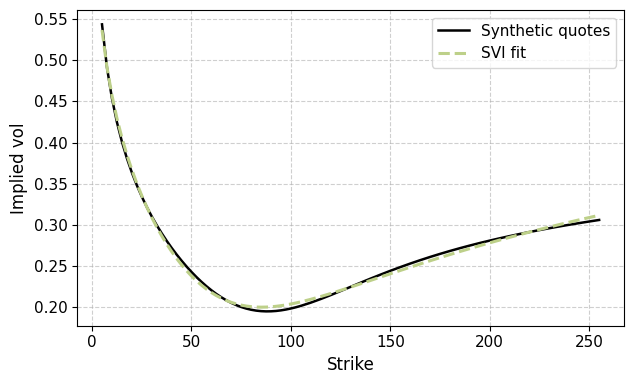

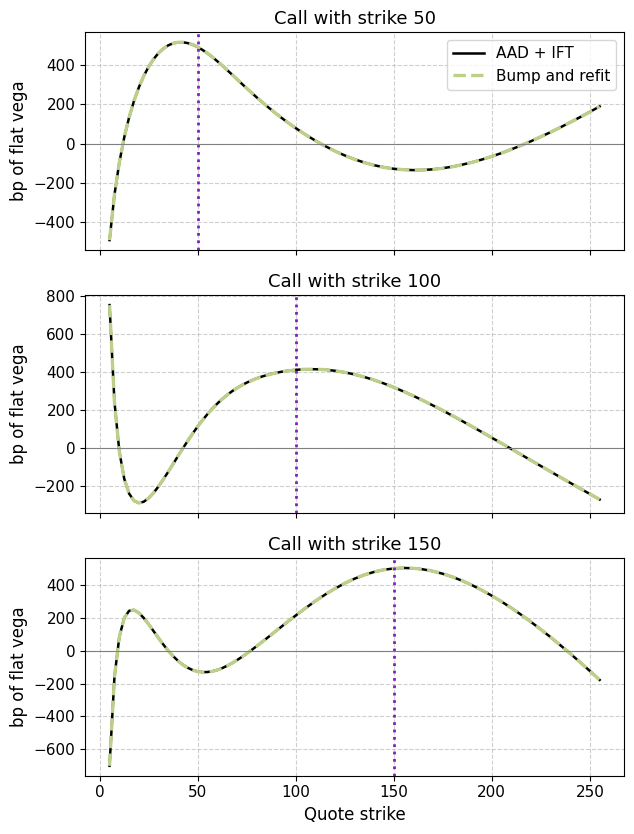

In [6]:
fig, ax = mpl.subplots(figsize=(6.5, 4))
ax.plot(strikes, ivs, color="k", label="Synthetic quotes")
ax.plot(strikes, base.bsvol(zs), color="#BDD089", ls="--", lw=2.2, label="SVI fit")
ax.set_xlabel("Strike"); ax.set_ylabel("Implied vol"); ax.grid(); ax.legend()
fig.tight_layout(); fig.savefig(IMG + "202612_smile.svg", bbox_inches="tight"); mpl.show()

fig, ax = mpl.subplots(3, 1, figsize=(6.5, 8.5), sharex=True)
for axi, k in zip(ax, [50, 100, 150]):
    base.bscall(spot, k, r, tau)
    vegas = base.pricing_results["vegas"]
    scaled = 1e4 * vegas / np.sum(vegas)  # same scale for every option
    axi.plot(strikes, scaled, color="k", label="AAD + IFT")
    axi.plot(strikes, 1e4 * bumped[k] / np.sum(vegas), color="#BDD089", ls="--", lw=2.4, label="Bump and refit")
    axi.axvline(k, ls="dotted", color="#8320B8", lw=2)
    axi.axhline(0, color="grey", lw=0.8)
    axi.set_title(f"Call with strike {k}"); axi.set_ylabel("bp of flat vega"); axi.grid()
ax[0].legend(); ax[-1].set_xlabel("Quote strike")
fig.tight_layout(); fig.savefig(IMG + "202612_vegas.svg", bbox_inches="tight"); mpl.show()


flat: min variance 0.0480, max resid 72.3bp
   K=50: PV change 0.0074, linear 0.0050
   K=100: PV change 0.7601, linear 0.7594
   K=150: PV change 0.3200, linear 0.2916
skew: min variance 0.0382, max resid 69.5bp
   K=50: PV change -0.0021, linear -0.0025
   K=100: PV change -0.0140, linear -0.0144
   K=150: PV change 0.1661, linear 0.1599
smile: min variance 0.0392, max resid 46.7bp
   K=50: PV change 0.0019, linear 0.0017
   K=100: PV change -0.1003, linear -0.1157
   K=150: PV change 0.0903, linear 0.1103


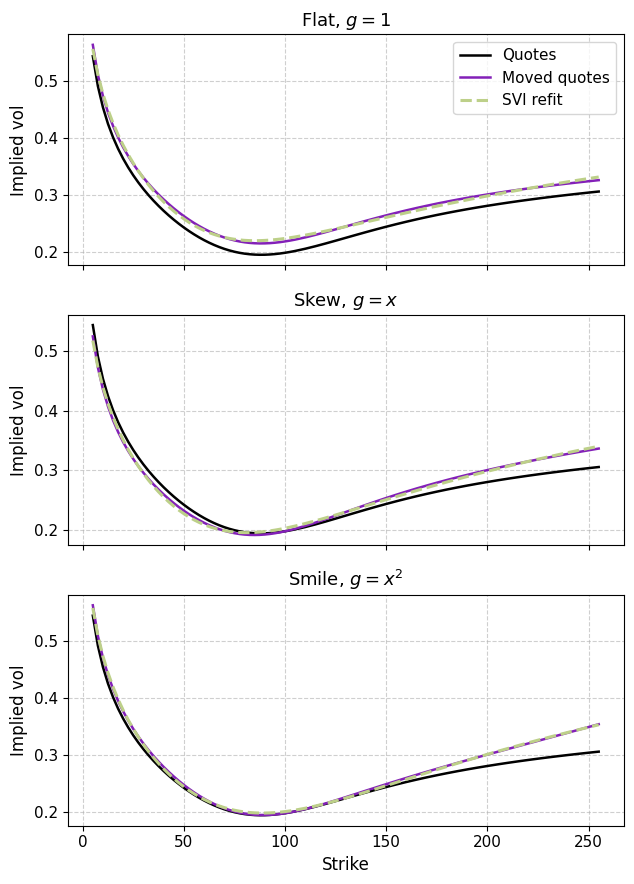

In [7]:
# before and after: quotes moved by eps * g, and the SVI refit to the moved quotes
eps = 0.02  # two vol points, large enough to see
fig, ax = mpl.subplots(3, 1, figsize=(6.5, 9), sharex=True)
titles = {"flat": "Flat, $g = 1$", "skew": "Skew, $g = x$", "smile": "Smile, $g = x^2$"}
for axi, (name, g) in zip(ax, shapes.items()):
    moved = ivs + eps * g
    sl = SliceSVI(tau)
    sl.fit(zs, moved, guess=base.params)
    print(f"{name}: min variance {sl.min_variance:.4f}, max resid {1e4 * np.abs(sl.bsvol(zs) - moved).max():.1f}bp")
    for k in [50, 100, 150]:
        base.bscall(spot, k, r, tau)
        sl.bscall(spot, k, r, tau)
        v = base.pricing_results["vegas"]
        dpv = sl.pricing_results["netvalue"] - base.pricing_results["netvalue"]
        print(f"   K={k}: PV change {dpv:.4f}, linear {eps * (v @ g):.4f}")
    axi.plot(strikes, ivs, color="k", label="Quotes")
    axi.plot(strikes, moved, color="#8320B8", label="Moved quotes")
    axi.plot(strikes, sl.bsvol(zs), color="#BDD089", ls="--", lw=2.2, label="SVI refit")
    axi.set_title(titles[name]); axi.set_ylabel("Implied vol"); axi.grid()
ax[0].legend(); ax[-1].set_xlabel("Strike")
fig.tight_layout(); fig.savefig(IMG + "202612_moves.svg", bbox_inches="tight"); mpl.show()


tanh smile (this post): params [-0.0737  0.1183 -0.0359 -0.2295  0.9596], flat vega 37.9704
SVI, skewed: params [ 0.0196  0.0404 -0.1483  0.0733  0.489 ], flat vega 38.1924
SVI, symmetric: params [ 0.02  0.04  0.   -0.    0.5 ], flat vega 38.2047
SVI, almost flat: params [ 0.0198  0.009  -0.1111  0.2469  2.2085], flat vega 38.4128


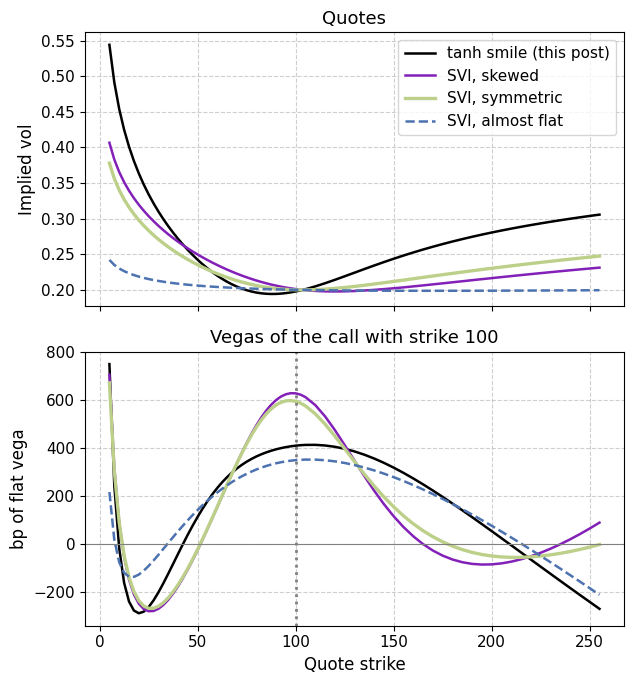

In [8]:
# the vegas are the least-squares weights h_i = j_i^T A^{-1} j* times 2 T sigma_i: they depend on the
# parametrization, the grid and theta, and only weakly on the smile. 100 call for four smiles.
def svi_smile(z, V=0.20, K=-0.30, S=1.00):  # exactly an SVI slice
    u = (1 + K * z) / 2
    return V * np.sqrt(u + np.sqrt(u**2 + S * z**2))

smiles = [
    ("tanh smile (this post)", ivs, dict(color="k")),
    ("SVI, skewed", svi_smile(zs), dict(color="#8320B8")),
    ("SVI, symmetric", svi_smile(zs, K=0.0), dict(color="#BDD089", lw=2.4)),
    ("SVI, almost flat", svi_smile(zs, K=-0.05, S=0.05), dict(color="#4C72B0", ls="--")),
]
fig, ax = mpl.subplots(2, 1, figsize=(6.5, 7), sharex=True)
for name, iv, kw in smiles:
    sl = SliceSVI(tau); sl.fit(zs, iv)
    sl.bscall(spot, 100, r, tau)
    v = sl.pricing_results["vegas"]
    print(f"{name}: params {np.round(sl.params, 4)}, flat vega {np.sum(v):.4f}")
    ax[0].plot(strikes, iv, label=name, **kw)
    ax[1].plot(strikes, 1e4 * v / np.sum(v), **kw)
ax[1].axvline(100, ls="dotted", color="grey", lw=2); ax[1].axhline(0, color="grey", lw=0.8)
ax[0].set_ylabel("Implied vol"); ax[0].set_title("Quotes"); ax[0].legend(); ax[0].grid()
ax[1].set_ylabel("bp of flat vega"); ax[1].set_title("Vegas of the call with strike 100"); ax[1].grid()
ax[1].set_xlabel("Quote strike")
fig.tight_layout(); fig.savefig(IMG + "202612_kernel.svg", bbox_inches="tight"); mpl.show()


## Parametrization as part of the model
SVI vs a natural cubic spline in total variance through all quotes (follows every quote move).

In [9]:
from scipy.interpolate import CubicSpline

def call_undisc(k, sig):
    d1 = (np.log(fwd / k) + 0.5 * sig**2 * tau) / (sig * np.sqrt(tau))
    return fwd * norm.cdf(d1) - k * norm.cdf(d1 - sig * np.sqrt(tau))

def spline_w(iv):
    return CubicSpline(zs, tau * iv**2, bc_type="natural")

def pv_spline(iv, k):
    return np.exp(-r * tau) * call_undisc(k, np.sqrt(spline_w(iv)(np.log(k / fwd)) / tau))

far_share = {}
for k in [50, 100, 150]:
    base.bscall(spot, k, r, tau)
    v_svi = base.pricing_results["vegas"]
    v_spl = np.array([(pv_spline(ivs + 1e-4 * e, k) - pv_spline(ivs - 1e-4 * e, k)) / 2e-4 for e in np.eye(len(ivs))])
    far = np.abs(strikes - k) > 30
    print(f"K={k}")
    for name, g in shapes.items():
        print(f"   {name:5s} SVI {v_svi @ g:9.4f}   spline {v_spl @ g:9.4f}")
    print(f"   share of sum|vega| on quotes > 30 strikes away: SVI {np.abs(v_svi[far]).sum() / np.abs(v_svi).sum():.3f}, "
          f"spline {np.abs(v_spl[far]).sum() / np.abs(v_spl).sum():.3f}")
    print(f"   |vega| far away / flat vega: SVI {np.abs(v_svi[far]).sum() / np.sum(v_svi):.3f}")


K=50
   flat  SVI    0.2497   spline    0.3011
   skew  SVI   -0.1258   spline   -0.1505
   smile SVI    0.0840   spline    0.0753
   share of sum|vega| on quotes > 30 strikes away: SVI 0.334, spline 0.000
   |vega| far away / flat vega: SVI 0.516
K=100
   flat  SVI   37.9704   spline   38.4049
   skew  SVI   -0.7205   spline    0.0000
   smile SVI   -5.7831   spline    0.0000
   share of sum|vega| on quotes > 30 strikes away: SVI 0.559, spline 0.000
   |vega| far away / flat vega: SVI 0.980
K=150
   flat  SVI   14.5796   spline   15.0080
   skew  SVI    7.9951   spline    7.5040
   smile SVI    5.5162   spline    3.7520
   share of sum|vega| on quotes > 30 strikes away: SVI 0.603, spline 0.000
   |vega| far away / flat vega: SVI 0.924


In [10]:
# one-quote bumps: does the refitted slice still have a nonnegative density?
Kf = np.linspace(6, 250, 4000)

def min_density(wfun):
    sig = np.sqrt(np.maximum(wfun(np.log(Kf / fwd)), 1e-12) / tau)
    return np.gradient(np.gradient(call_undisc(Kf, sig), Kf), Kf).min()

print("base: spline", min_density(spline_w(ivs)), " SVI", min_density(base.bstermvar))
for bp in [10, 25, 50]:
    bad_spl = bad_svi = 0
    for i in range(len(ivs)):
        for sg in (1, -1):
            iv = ivs.copy(); iv[i] += sg * bp * 1e-4
            bad_spl += min_density(spline_w(iv)) < 0
            sl = SliceSVI(tau); sl.fit(zs, iv, guess=base.params)
            bad_svi += min_density(sl.bstermvar) < 0
    print(f"{bp}bp one-quote bumps: negative density in {bad_spl}/{2 * len(ivs)} spline, {bad_svi}/{2 * len(ivs)} SVI refits")


base: spline 6.101648638531498e-09  SVI 9.441923991294085e-09
10bp one-quote bumps: negative density in 60/142 spline, 0/142 SVI refits
25bp one-quote bumps: negative density in 131/142 spline, 0/142 SVI refits
50bp one-quote bumps: negative density in 139/142 spline, 0/142 SVI refits
